In [ ]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import optuna
import pacmap
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

from pyDRMetrics.pyDRMetrics import DRMetrics

from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

c:\Users\willi\meu_projeto_python\Dissertação\RBras\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [9]:
def calcular_metricas_reducao(X, Z):

    dr_metrics = DRMetrics(X, Z)

    q_local = dr_metrics.Qlocal
    auc_qnn = dr_metrics.AUC

    return q_local, auc_qnn


def calcular_score_reducao(X, Z):

    q_local, auc_qnn = calcular_metricas_reducao(X, Z)

    score = 0.5 * q_local + 0.5 * auc_qnn

    return score, q_local, auc_qnn


def calcular_metricas_clustering(Z, labels):

    n_clusters = len(np.unique(labels))

    if n_clusters < 2 or n_clusters >= len(labels):
        raise ValueError("Número inválido de clusters.")

    sil_score = silhouette_score(Z, labels)

    ch_score = calinski_harabasz_score(Z, labels)

    ch_score_norm = ch_score / (ch_score + 1000)

    return sil_score, ch_score, ch_score_norm


def calcular_score_clustering(Z, labels):

    sil_score, ch_score, ch_score_norm = (
        calcular_metricas_clustering(Z, labels)
    )

    score = 0.5 * sil_score + 0.5 * ch_score_norm

    return score, sil_score, ch_score, ch_score_norm

In [8]:
from pathlib import Path
import json
import optuna
import pandas as pd
import numpy as np

from sklearn.metrics import adjusted_rand_score


# ============================================================
# Diretórios
# ============================================================

PROJECT_DIR = Path.cwd().parent

DATA_DIR = PROJECT_DIR / "data" / "processed"
RESULTS_DIR = PROJECT_DIR / "results"

OPTUNA_DIR = RESULTS_DIR / "optuna"
EMBEDDINGS_DIR = RESULTS_DIR / "embeddings"
METRICS_DIR = RESULTS_DIR / "metrics"
FIGURES_DIR = RESULTS_DIR / "figures"


# ============================================================
# Carregamento da base e dados clínicos
# ============================================================

df = pd.read_csv(
    DATA_DIR / "mad_datasets" / "VST_MAD_3000.csv",
    index_col=0
)

clinical_final = pd.read_csv(
    DATA_DIR / "clinical_final.csv",
    index_col=0
)

clinical_final = clinical_final[["SUBTYPE"]]
clinical_final = clinical_final.loc[df.index]

X_data = df.values
y_true = clinical_final["SUBTYPE"].values


# ============================================================
# Recupera os estudos Optuna
# ============================================================

study_joint = optuna.load_study(
    study_name="Joint_VST_MAD_3000",
    storage=f"sqlite:///{OPTUNA_DIR / 'joint_vst_mad_3000.db'}"
)

study_pacmap = optuna.load_study(
    study_name="PaCMAP_VST_MAD_3000",
    storage=f"sqlite:///{OPTUNA_DIR / 'pacmap_vst_mad_3000.db'}"
)

study_gmm = optuna.load_study(
    study_name="GMM_VST_MAD_3000",
    storage=f"sqlite:///{OPTUNA_DIR / 'gmm_vst_mad_3000.db'}"
)


# ============================================================
# Recupera os melhores hiperparâmetros
# ============================================================

best_params_joint = study_joint.best_params

best_params_pacmap = study_pacmap.best_params

best_params_gmm = study_gmm.best_params


# ============================================================
# Recupera os embeddings salvos
# ============================================================

embedding_joint = pd.read_csv(
    EMBEDDINGS_DIR / "embedding_joint_vst_mad_3000.csv",
    index_col=0
)

embedding_decoupled = pd.read_csv(
    EMBEDDINGS_DIR / "embedding_decoupled_vst_mad_3000.csv",
    index_col=0
)


# ============================================================
# Separa coordenadas e rótulos
# ============================================================

Z_joint = embedding_joint.drop(
    columns=["Cluster", "SUBTYPE"]
).values

labels_joint = embedding_joint["Cluster"].values

Z_decoupled = embedding_decoupled.drop(
    columns=["Cluster", "SUBTYPE"]
).values

labels_decoupled = embedding_decoupled["Cluster"].values


# ============================================================
# Verificações de alinhamento
# ============================================================

assert embedding_joint.index.equals(df.index)
assert embedding_decoupled.index.equals(df.index)

assert np.array_equal(
    embedding_joint["SUBTYPE"].values,
    y_true
)

assert np.array_equal(
    embedding_decoupled["SUBTYPE"].values,
    y_true
)


# ============================================================
# Métricas da estratégia Joint
# ============================================================

best_trial_joint = study_joint.best_trial

q_local_joint = best_trial_joint.user_attrs["Qlocal"]
auc_qnn_joint = best_trial_joint.user_attrs["AUC_QNN"]

sil_joint = best_trial_joint.user_attrs["Silhouette"]

ch_joint = best_trial_joint.user_attrs["Calinski_Harabasz"]

ari_joint = adjusted_rand_score(
    y_true,
    labels_joint
)


# ============================================================
# Métricas da estratégia em duas etapas
# ============================================================

score_dr_decoupled, q_local_decoupled, auc_qnn_decoupled = (
    calcular_score_reducao(X_data, Z_decoupled)
)

score_gmm_decoupled, sil_decoupled, ch_decoupled, ch_norm_decoupled = (
    calcular_score_clustering(Z_decoupled, labels_decoupled)
)

ari_decoupled = adjusted_rand_score(
    y_true,
    labels_decoupled
)


print("Resultados carregados com sucesso!")

NameError: name 'calcular_score_reducao' is not defined

In [10]:
PROJECT_DIR = Path.cwd().parent

DATA_DIR = PROJECT_DIR / "data" / "processed"
RESULTS_DIR = PROJECT_DIR / "results"

OPTUNA_DIR = RESULTS_DIR / "optuna"
EMBEDDINGS_DIR = RESULTS_DIR / "embeddings"
METRICS_DIR = RESULTS_DIR / "metrics"
FIGURES_DIR = RESULTS_DIR / "figures"

for directory in [
    OPTUNA_DIR,
    EMBEDDINGS_DIR,
    METRICS_DIR,
    FIGURES_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)
    
    
# ============================================================
# Recupera os estudos Optuna
# ============================================================

study_joint = optuna.load_study(
    study_name="Joint_VST_MAD_3000",
    storage=f"sqlite:///{OPTUNA_DIR / 'joint_vst_mad_3000.db'}"
)

# ============================================================
# Recupera os hiperparâmetros
# ============================================================

with open(
    OPTUNA_DIR / "best_params_joint_vst_mad_3000.json",
    "r"
) as file:
    best_params_joint = json.load(file)

with open(
    OPTUNA_DIR / "best_params_pacmap_vst_mad_3000.json",
    "r"
) as file:
    best_params_pacmap = json.load(file)

with open(
    OPTUNA_DIR / "best_params_gmm_vst_mad_3000.json",
    "r"
) as file:
    best_params_gmm = json.load(file)


# ============================================================
# Recupera as métricas da estratégia de duas etapas
# ============================================================

score_dr_decoupled, q_local_decoupled, auc_qnn_decoupled = (
    calcular_score_reducao(X_data, Z_decoupled)
)

score_gmm_decoupled, sil_decoupled, ch_decoupled, ch_norm_decoupled = (
    calcular_score_clustering(Z_decoupled, labels_decoupled)
)

ari_decoupled = adjusted_rand_score(
    y_true,
    labels_decoupled
)

In [11]:
best_trial_joint = study_joint.best_trial

q_local_joint = best_trial_joint.user_attrs["Qlocal"]
auc_qnn_joint = best_trial_joint.user_attrs["AUC_QNN"]
sil_joint = best_trial_joint.user_attrs["Silhouette"]
ch_joint = best_trial_joint.user_attrs["Calinski_Harabasz"]

ari_joint = adjusted_rand_score(
    y_true,
    labels_joint
)

In [12]:
embedding_joint = pd.read_csv(
    EMBEDDINGS_DIR / "embedding_joint_vst_mad_3000.csv",
    index_col=0
)

embedding_decoupled = pd.read_csv(
    EMBEDDINGS_DIR / "embedding_decoupled_vst_mad_3000.csv",
    index_col=0
)

# Recupera os rótulos dos clusters
labels_joint = embedding_joint["Cluster"].values
labels_decoupled = embedding_decoupled["Cluster"].values

# Recupera os subtipos clínicos
y_true = embedding_joint["SUBTYPE"].values

# Recupera as coordenadas dos embeddings
Z_joint = embedding_joint.drop(columns=["Cluster", "SUBTYPE"]).values

Z_decoupled = embedding_decoupled.drop(
    columns=["Cluster", "SUBTYPE"]
).values

# Confere o alinhamento
assert embedding_joint.index.equals(embedding_decoupled.index)
assert embedding_joint.index.equals(clinical_final.index)

## Tabela de Contingência

In [13]:
contingency_joint = pd.crosstab(
    pd.Series(y_true, name="Subtype"),
    pd.Series(labels_joint, name="Cluster")
)

contingency_decoupled = pd.crosstab(
    pd.Series(y_true, name="Subtype"),
    pd.Series(labels_decoupled, name="Cluster")
)

print("Tabela de contingência - Joint")
display(contingency_joint)

print("\nTabela de contingência - Duas etapas")
display(contingency_decoupled)

Tabela de contingência - Joint


Cluster,0,1
Subtype,,
BRCA_Basal,167,4
BRCA_Her2,0,77
BRCA_LumA,0,494
BRCA_LumB,0,193
BRCA_Normal,4,31



Tabela de contingência - Duas etapas


Cluster,0,1
Subtype,,
BRCA_Basal,165,6
BRCA_Her2,0,77
BRCA_LumA,0,494
BRCA_LumB,0,193
BRCA_Normal,4,31


## Mapas de Calor

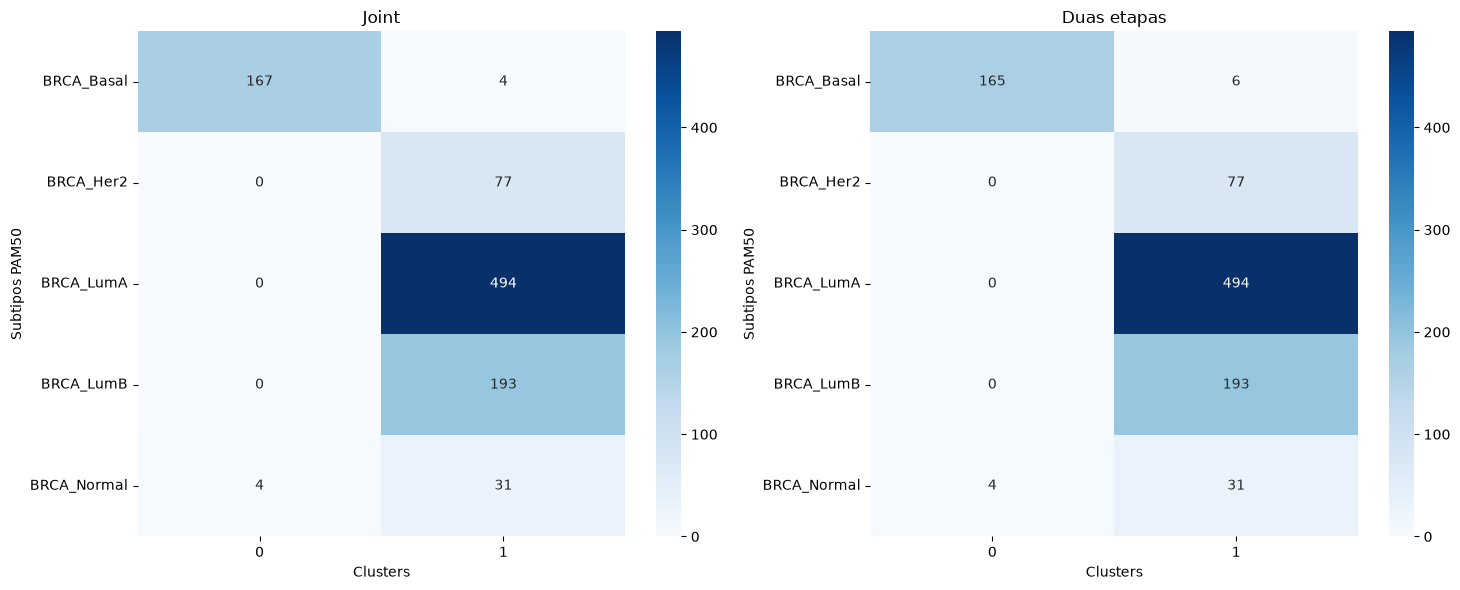

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(
    contingency_joint,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title("Joint")
axes[0].set_xlabel("Clusters")
axes[0].set_ylabel("Subtipos PAM50")

sns.heatmap(
    contingency_decoupled,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[1]
)

axes[1].set_title("Duas etapas")
axes[1].set_xlabel("Clusters")
axes[1].set_ylabel("Subtipos PAM50")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "contingency_vst_mad_3000.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Plot dos Embeddings

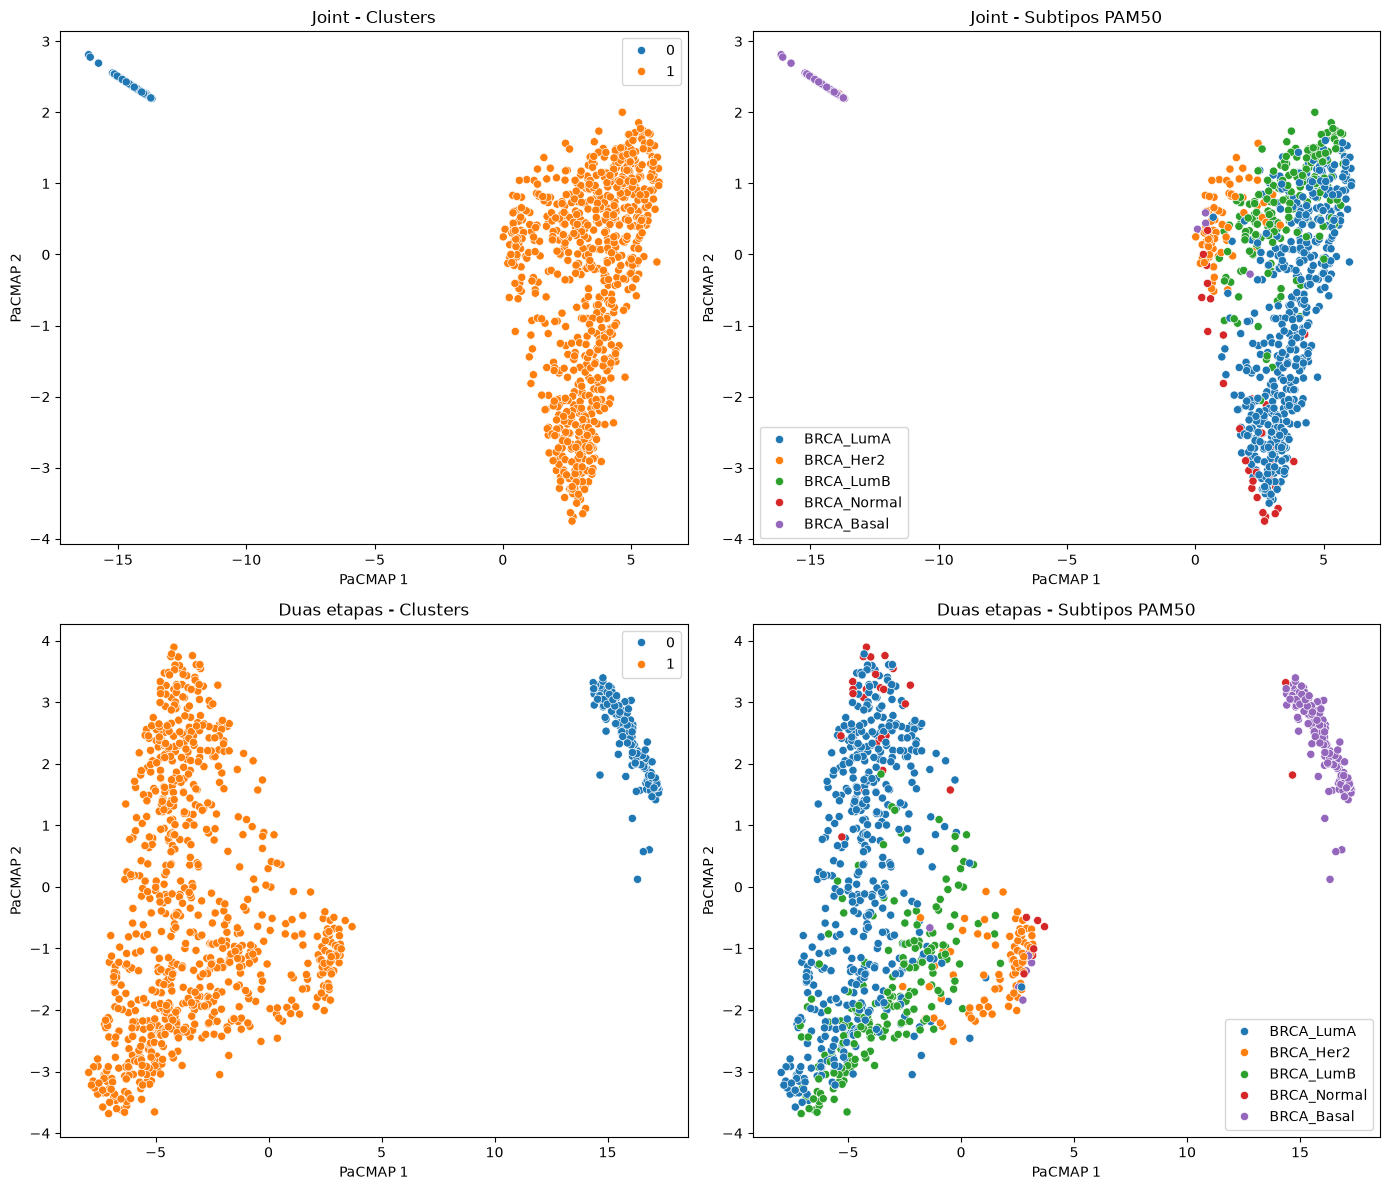

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Joint - clusters
sns.scatterplot(
    x=Z_joint[:, 0],
    y=Z_joint[:, 1],
    hue=labels_joint,
    palette="tab10",
    s=35,
    ax=axes[0, 0],
    legend="full"
)

axes[0, 0].set_title("Joint - Clusters")
axes[0, 0].set_xlabel("PaCMAP 1")
axes[0, 0].set_ylabel("PaCMAP 2")

# Joint - subtipos
sns.scatterplot(
    x=Z_joint[:, 0],
    y=Z_joint[:, 1],
    hue=y_true,
    palette="tab10",
    s=35,
    ax=axes[0, 1],
    legend="full"
)

axes[0, 1].set_title("Joint - Subtipos PAM50")
axes[0, 1].set_xlabel("PaCMAP 1")
axes[0, 1].set_ylabel("PaCMAP 2")

# Duas etapas - clusters
sns.scatterplot(
    x=Z_decoupled[:, 0],
    y=Z_decoupled[:, 1],
    hue=labels_decoupled,
    palette="tab10",
    s=35,
    ax=axes[1, 0],
    legend="full"
)

axes[1, 0].set_title("Duas etapas - Clusters")
axes[1, 0].set_xlabel("PaCMAP 1")
axes[1, 0].set_ylabel("PaCMAP 2")

# Duas etapas - subtipos
sns.scatterplot(
    x=Z_decoupled[:, 0],
    y=Z_decoupled[:, 1],
    hue=y_true,
    palette="tab10",
    s=35,
    ax=axes[1, 1],
    legend="full"
)

axes[1, 1].set_title("Duas etapas - Subtipos PAM50")
axes[1, 1].set_xlabel("PaCMAP 1")
axes[1, 1].set_ylabel("PaCMAP 2")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "embeddings_vst_mad_3000.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Comparação das Métricas

In [16]:
# Recupera as métricas dos melhores ensaios Joint
best_trial_joint = study_joint.best_trial

results_comparison = pd.DataFrame({
    "Estratégia": [
        "Joint",
        "Duas etapas"
    ],

    "Qlocal": [
        best_trial_joint.user_attrs["Qlocal"],
        q_local_decoupled
    ],

    "AUC QNN": [
        best_trial_joint.user_attrs["AUC_QNN"],
        auc_qnn_decoupled
    ],

    "Silhouette": [
        best_trial_joint.user_attrs["Silhouette"],
        sil_decoupled
    ],

    "Calinski-Harabasz": [
        best_trial_joint.user_attrs["Calinski_Harabasz"],
        ch_decoupled
    ],

    "ARI": [
        adjusted_rand_score(y_true, labels_joint),
        ari_decoupled
    ],

    "Número de clusters": [
        len(np.unique(labels_joint)),
        len(np.unique(labels_decoupled))
    ]
})

display(results_comparison.round(4))

results_comparison.to_csv(
    METRICS_DIR / "comparison_vst_mad_3000.csv",
    index=False
)

results_comparison.to_excel(
    METRICS_DIR / "comparison_vst_mad_3000.xlsx",
    index=False
)

,Estratégia,Qlocal,AUC QNN,Silhouette,Calinski-Harabasz,ARI,Número de clusters
0,Joint,0.4134,0.7537,0.8725,12733.0132,0.3388,2
1,Duas etapas,0.4420,0.7507,0.7662,3999.6978,0.3327,2


## Comparação dos parâmetros

In [17]:
params_comparison = pd.DataFrame([
    {
        "Estratégia": "Joint",
        **best_params_joint
    },
    {
        "Estratégia": "Duas etapas",
        **{
            "n_neighbors": best_params_pacmap["n_neighbors"],
            "MN_ratio": best_params_pacmap["MN_ratio"],
            "FP_ratio": best_params_pacmap["FP_ratio"],
            "n_components": best_params_pacmap["n_components"],
            "gmm_n_components": best_params_gmm["n_components"],
            "covariance_type": best_params_gmm["covariance_type"],
            "n_init": best_params_gmm["n_init"]
        }
    }
])

display(params_comparison)

params_comparison.to_csv(
    METRICS_DIR / "hyperparameters_vst_mad_3000.csv",
    index=False
)

,Estratégia,n_neighbors,MN_ratio,FP_ratio,n_components,gmm_n_components,covariance_type,n_init
0,Joint,94,0.219072,1.457864,7,2,diag,9
1,Duas etapas,34,2.789708,3.837546,9,2,full,10
